In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
# Permite importar tu paquete de src/ sin instalarlo
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

# 07 · Validación e interpretación — abrir la prueba, una sola vez

Hasta aquí todo se decidió con **validación**: el torneo (etapa 5) y la búsqueda con sedes reservadas (etapa 6). La
**prueba** (el 20 % de las sedes que nadie ha mirado, `data/processed/test.joblib`) se abre hoy, **una sola vez**, para medir
cómo se comportará el modelo con colegios nuevos. El orden importa:

1. Las decisiones (modelo, parámetros, línea base, metas, regla de equidad) se **escriben y se guardan con fecha y hora**.
2. Recién entonces se abre la prueba. Su resultado **no se usa para volver a decidir**: si algo sale mal, se anota como límite.
3. No basta un número: **intervalo** (remuestreando **sedes**), comparación con la **línea base**, **equidad por segmento** y
   **por qué** estima así el modelo.

Reglas completas: `especificaciones/07-validacion.md` (sección 1 aprobada por el grupo el 5 nov 2026).

In [2]:
import json
from datetime import datetime

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

from proyecto.data.split import GROUP_COL
from proyecto.models.evaluation import (
    CLEAR, FAILS, INCONCLUSIVE, bootstrap_metric_difference, equity_segments, equity_table, model_columns,
    permutation_importance_table,
)
from proyecto.models.train import TARGET, feature_frame, regression_metrics
from proyecto.models.tuning import bootstrap_mae_difference, bootstrap_metric_ci, build_tuned_pipeline

ROOT = Path.cwd().resolve().parent
REPORTS_DIR = ROOT / "reports"
PROCESSED_DIR = ROOT / "data" / "processed"
MODELS_DIR = ROOT / "models"
TRAIN_PATH = PROCESSED_DIR / "train.joblib"
TEST_PATH = PROCESSED_DIR / "test.joblib"                # se abre UNA vez, en la sección 4
MARKER = REPORTS_DIR / "prueba_abierta.txt"              # constancia de cuándo se abrió
CACHE = PROCESSED_DIR / "prueba_resultados.joblib"       # predicciones e importancias de la prueba (no se sube a Git)
FINGERPRINTS = REPORTS_DIR / "prueba_huellas.json"       # huellas SHA-256 de la prueba, el modelo y los resultados
MODEL_PATH = MODELS_DIR / "final_pipeline.joblib"


def sha256(path):
    """Huella digital de un archivo: cambia si cambia un solo byte. Solo lee bytes; no evalúa nada."""
    import hashlib
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()
print("ID_COL:", GROUP_COL, "· TARGET:", TARGET)

ID_COL: cole_cod_dane_sede · TARGET: punt_global


## 0. Datos de entrenamiento

Todo `train.joblib` (búsqueda + sedes reservadas de la etapa 6). La prueba sigue cerrada.

In [3]:
train = joblib.load(TRAIN_PATH)
X_train, y_train = feature_frame(train)
print(f"entrenamiento: {len(train):,} estudiantes · {train[GROUP_COL].nunique():,} sedes")

entrenamiento: 57,286 estudiantes · 1,155 sedes


## 1. Decisiones congeladas — **antes** de abrir la prueba

Salen de las etapas 5 y 6 (validación por sede), nunca de la prueba:

- **Modelo final:** `HistGradientBoostingRegressor` con los **parámetros optimizados** de `reports/06_best_params.json`
  (regla 1 de la etapa 6: mejora en sedes reservadas con IC [−0,640 ; −0,118]; regla 2: empate con XGBoost y desempate a
  favor de HistGradientBoosting).
- **Calibración y regla de decisión:** no aplican (regresión: la app muestra el puntaje estimado).
- **Métrica principal:** MAE en puntos; controles RMSE y R².
- **Línea base:** predecir siempre la mediana del entrenamiento (`DummyRegressor(strategy="median")`).
- **Metas:** MAE ≤ 38 (mínima) y ≤ 35 (deseable).
- **Regla de equidad:** un segmento **cumple** si el MAE del modelo es **estrictamente menor** que el de la línea base. Los que
  cumplen se clasifican con el intervalo del 95 % (por sedes) de la diferencia: **«cumple con ventaja clara»** si excluye el
  cero, **«cumple sin ventaja concluyente»** si lo incluye. El intervalo no cambia el veredicto.

Se guardan en `reports/07_decisiones_congeladas.json` con fecha y hora. Si la prueba ya se abrió, no se reescriben.

In [4]:
best = json.loads((REPORTS_DIR / "06_best_params.json").read_text(encoding="utf-8"))
FINAL_NAME = best["modelo_final"]["elegido"]
assert FINAL_NAME == "hist gradient boosting" and best[FINAL_NAME]["parametros_elegidos"] == "optimizados"
DECISIONS_PATH = REPORTS_DIR / "07_decisiones_congeladas.json"

decisions = {
    "fecha_y_hora": datetime.now().isoformat(timespec="seconds"),
    "modelo_final": FINAL_NAME,
    "parametros": best[FINAL_NAME]["params"],
    "fijos": {"early_stopping": False, "random_state": 42},
    "entrenamiento": "todo train.joblib (búsqueda + sedes reservadas de la etapa 6)",
    "calibrar": "no aplica (regresión)",
    "regla_de_decision": "no aplica (regresión: se muestra el puntaje estimado)",
    "metrica_principal": "MAE (puntos); controles RMSE y R²",
    "linea_base": "DummyRegressor(strategy='median') ajustado con todo el entrenamiento",
    "metas": {"minima": 38, "deseable": 35},
    "regla_equidad": ("cumple si MAE modelo < MAE línea base en el segmento; si cumple: 'con ventaja clara' si el IC 95 % "
                      "(sedes) de la diferencia excluye el cero, 'sin ventaja concluyente' si lo incluye"),
    "como_se_decidio": "etapas 5 y 6 con validación agrupada por sede; la prueba no se miró",
}
# H1 (auditoría etapa 7): si la prueba ya se abrió, las decisiones NUNCA se reescriben. Sin su archivo, se detiene.
if MARKER.exists() and not DECISIONS_PATH.exists():
    raise RuntimeError("La prueba ya se abrió y falta 07_decisiones_congeladas.json: recupéralo de Git; no se reescribe.")
if MARKER.exists():
    frozen = json.loads(DECISIONS_PATH.read_text(encoding="utf-8"))
    if frozen["parametros"] != decisions["parametros"] or frozen["modelo_final"] != decisions["modelo_final"]:
        raise RuntimeError("06_best_params.json ya no coincide con las decisiones congeladas antes de abrir la prueba.")
    decisions = frozen                                                    # la prueba ya se abrió: no se reescriben
    print("Las decisiones ya estaban congeladas el", decisions["fecha_y_hora"], "(no se modifican).")
else:
    DECISIONS_PATH.write_text(json.dumps(decisions, indent=2, ensure_ascii=False), encoding="utf-8")
    print("Decisiones congeladas:", decisions["fecha_y_hora"])
for k, v in decisions["parametros"].items():
    print(f"    {k:20s} {v}")

Las decisiones ya estaban congeladas el 2026-11-05T19:53:16 (no se modifican).
    min_frequency        0.001
    loss                 absolute_error
    learning_rate        0.030107008010973057
    max_iter             587
    max_leaf_nodes       16
    min_samples_leaf     82
    l2_regularization    0.36568458128692466
    max_features         0.6154550174376242


## 2. ¿Calibrar?

No aplica: es **regresión**. No hay probabilidades ni umbral que calibrar; la app muestra el puntaje estimado.

## 3. Entrenar el modelo final con **todo** el entrenamiento

Mismo pipeline de la etapa 6 (preprocesamiento con `min_frequency` 0,1 % + modelo), ajustado con los 57.286 estudiantes.
También se ajusta la **línea base** (la mediana del entrenamiento). El pipeline completo se guarda en
`models/final_pipeline.joblib` (no se sube a Git; el notebook 08 lo registra y exporta).

In [5]:
# H4 (auditoría etapa 7): si la prueba ya se abrió, NO se reentrena: se carga el modelo evaluado y se verifica su huella.
if MARKER.exists():
    if not FINGERPRINTS.exists():   # auditoría etapa 8, H2: sin huellas no se puede verificar nada
        raise RuntimeError("La prueba ya se abrió y falta reports/prueba_huellas.json: recupéralo de Git.")
    if FINGERPRINTS.exists():
        expected = json.loads(FINGERPRINTS.read_text(encoding="utf-8"))["final_pipeline.joblib"]
        assert sha256(MODEL_PATH) == expected, "final_pipeline.joblib no es el modelo que se evaluó con la prueba"
    final_model = joblib.load(MODEL_PATH)
    print("La prueba ya se abrió: se carga el modelo evaluado (no se reentrena).")
else:
    final_model = build_tuned_pipeline(decisions["modelo_final"], decisions["parametros"]).fit(X_train, y_train)
    joblib.dump(final_model, MODEL_PATH)
baseline = DummyRegressor(strategy="median").fit(X_train, y_train)   # mediana del entrenamiento: no depende de la prueba

fitted = final_model.named_steps["model"].get_params()
assert all(fitted[k] == v for k, v in decisions["parametros"].items() if k != "min_frequency")
# H6 (auditoría etapa 7): el umbral de poco frecuentes vive en el preprocesador, no en el modelo
onehot = final_model.named_steps["prep"].named_transformers_["cat"].named_steps["onehot"]
assert onehot.min_frequency == decisions["parametros"]["min_frequency"], "el umbral del preprocesador no es el decidido"
print("modelo final ajustado:", type(final_model.named_steps["model"]).__name__, "· pérdida:", fitted["loss"])
print(f"línea base: siempre {float(baseline.constant_.ravel()[0]):.0f} puntos (mediana del entrenamiento)")

La prueba ya se abrió: se carga el modelo evaluado (no se reentrena).
modelo final ajustado: HistGradientBoostingRegressor · pérdida: absolute_error
línea base: siempre 243 puntos (mediana del entrenamiento)


## 4. Abrir la prueba — **una sola vez**

Esta celda abre `test.joblib`, escribe la marca `reports/prueba_abierta.txt` y guarda en `data/processed/` todo lo que se
necesita de la prueba: las predicciones del modelo y de la línea base, los segmentos, las sedes y la importancia por
permutación (sección 7). Si el notebook se vuelve a ejecutar, **no vuelve a abrir la prueba**: reutiliza lo guardado y lo dice.

In [6]:
if MARKER.exists() and CACHE.exists():
    if FINGERPRINTS.exists():   # H3: los resultados guardados deben ser los de la apertura
        expected = json.loads(FINGERPRINTS.read_text(encoding="utf-8"))["prueba_resultados.joblib"]
        assert sha256(CACHE) == expected, "prueba_resultados.joblib cambió desde la apertura"
    results = joblib.load(CACHE)
    print("La prueba ya se abrió:", MARKER.read_text(encoding="utf-8").strip())
    print("Se reutilizan sus resultados guardados; no se vuelve a evaluar el modelo con la prueba.")
elif MARKER.exists():
    raise RuntimeError("La prueba ya se abrió y no hay resultados guardados: declararlo en el reporte antes de reabrirla.")
else:
    # H3 (auditoría etapa 7): la marca se escribe ANTES de evaluar. Si algo falla a mitad, queda la marca sin resultados
    # y el notebook se detiene (rama de arriba) en vez de reabrir la prueba en silencio.
    MARKER.write_text(f"Prueba abierta el {datetime.now().isoformat(timespec='seconds')} · modelo "
                      f"{decisions['modelo_final']}. Una sola vez.\n", encoding="utf-8")
    test = joblib.load(TEST_PATH)
    X_test, y_test = feature_frame(test)
    assert set(test[GROUP_COL]).isdisjoint(set(train[GROUP_COL])), "una sede de la prueba está en el entrenamiento"
    cols = model_columns()
    results = {
        "y": y_test.to_numpy(),
        "pred_model": final_model.predict(X_test),
        "pred_base": baseline.predict(X_test),
        "groups": test[GROUP_COL].to_numpy(),
        "segments": equity_segments(test).reset_index(drop=True),
        # interpretación: cuánto sube el MAE al desordenar cada columna (5 repeticiones, semilla 42)
        "importance": permutation_importance_table(final_model, X_test[cols], y_test, cols, n_repeats=5),
    }
    joblib.dump(results, CACHE)
    FINGERPRINTS.write_text(json.dumps({
        "test.joblib": sha256(TEST_PATH), "final_pipeline.joblib": sha256(MODEL_PATH),
        "prueba_resultados.joblib": sha256(CACHE),
        "nota": f"calculadas al abrir la prueba: {len(test):,} estudiantes, {test[GROUP_COL].nunique():,} sedes",
    }, indent=2, ensure_ascii=False), encoding="utf-8")
    del test, X_test
    print("Prueba abierta ahora; marca escrita en", MARKER.name)

y_test, pred_model, pred_base, test_groups = results["y"], results["pred_model"], results["pred_base"], results["groups"]
print(f"prueba: {len(y_test):,} estudiantes · {pd.unique(test_groups).size:,} sedes (ninguna en el entrenamiento)")

La prueba ya se abrió: Prueba abierta el 2026-11-05T19:55:52 · modelo hist gradient boosting · 14,862 estudiantes, 289 sedes. Una sola vez.
Se reutilizan sus resultados guardados; no se vuelve a evaluar el modelo con la prueba.
prueba: 14,862 estudiantes · 289 sedes (ninguna en el entrenamiento)


## 5. Métricas, intervalos y comparación con la línea base

Intervalo del 95 % con 1.000 remuestreos de **sedes completas**. Diferencia = modelo − línea base: en MAE y RMSE, negativa es
mejor; en R², positiva es mejor.

In [7]:
m_model, m_base = regression_metrics(y_test, pred_model), regression_metrics(y_test, pred_base)
fns = {"mae": mean_absolute_error, "rmse": root_mean_squared_error, "r2": r2_score}
rows = []
for name, fn in fns.items():
    _, lo_m, hi_m = bootstrap_metric_ci(y_test, pred_model, test_groups, fn)
    _, lo_b, hi_b = bootstrap_metric_ci(y_test, pred_base, test_groups, fn)
    if name == "mae":
        diff, lo_d, hi_d = bootstrap_mae_difference(y_test, pred_model, pred_base, test_groups)
    else:
        diff, lo_d, hi_d = bootstrap_metric_difference(y_test, pred_model, pred_base, test_groups, fn)
    rows.append({"métrica": name.upper() if name != "r2" else "R²",
                 "modelo": m_model[name], "IC modelo": f"[{lo_m:.3f}; {hi_m:.3f}]",
                 "línea base": m_base[name], "IC línea base": f"[{lo_b:.3f}; {hi_b:.3f}]",
                 "diferencia": diff, "IC dif. inf.": lo_d, "IC dif. sup.": hi_d,
                 "_lo_m": lo_m, "_hi_m": hi_m, "_lo_b": lo_b, "_hi_b": hi_b})
metrics = pd.DataFrame(rows).set_index("métrica")
metrics.drop(columns=[c for c in metrics if c.startswith("_")]).round(3)

,modelo,IC modelo,línea base,IC línea base,diferencia,IC dif. inf.,IC dif. sup.
métrica,,,,,,,
MAE,33.316,[32.394; 34.207],43.088,[41.376; 44.980],-9.772,-11.781,-7.990
RMSE,41.463,[40.344; 42.496],51.971,[49.792; 54.367],-10.509,-12.738,-8.467
R²,0.363,[0.306; 0.414],-0.001,[-0.020; -0.000],0.364,0.309,0.421


In [8]:
mae, mae_hi = metrics.loc["MAE", "modelo"], metrics.loc["MAE", "_hi_m"]
beats_baseline = metrics.loc["MAE", "IC dif. sup."] < 0
print(f"¿Mejora a la línea base con confianza (todo el IC de la diferencia de MAE bajo cero)? {'SÍ' if beats_baseline else 'NO'}")
print(f"Meta mínima (MAE ≤ 38):   puntual {'cumple' if mae <= 38 else 'NO cumple'} ({mae:.2f}); "
      f"límite superior del IC {'cumple' if mae_hi <= 38 else 'NO cumple'} ({mae_hi:.2f})")
print(f"Meta deseable (MAE ≤ 35): puntual {'cumple' if mae <= 35 else 'NO cumple'} ({mae:.2f}); "
      f"límite superior del IC {'cumple' if mae_hi <= 35 else 'NO cumple'} ({mae_hi:.2f})")
print(f"Mejora frente a la línea base: {-metrics.loc['MAE', 'diferencia']:.2f} puntos "
      f"({-metrics.loc['MAE', 'diferencia'] / metrics.loc['MAE', 'línea base']:.1%})")

¿Mejora a la línea base con confianza (todo el IC de la diferencia de MAE bajo cero)? SÍ
Meta mínima (MAE ≤ 38):   puntual cumple (33.32); límite superior del IC cumple (34.21)
Meta deseable (MAE ≤ 35): puntual cumple (33.32); límite superior del IC cumple (34.21)
Mejora frente a la línea base: 9.77 puntos (22.7%)


## 6. Condición de equidad por segmento

Estrato (con «Sin Estrato» y «Sin dato (vacío)»), zona, naturaleza del colegio y género. Regla escrita antes de abrir la
prueba (sección 1). Cada segmento con su número de estudiantes y de sedes: con pocas sedes, el intervalo sale ancho.

In [9]:
equity = equity_table(y_test, pred_model, pred_base, results["segments"], test_groups)
pd.set_option("display.max_rows", 40)
equity.round(3)

estudiantes  sedes  mae_modelo  mae_linea_base  \
variable   segmento                                                           
estrato    Estrato 1                3068    245      31.924          39.171   
           Estrato 2                5453    258      33.433          40.086   
           Estrato 3                3637    245      34.189          44.161   
           Estrato 4                 800    169      35.567          54.978   
           Estrato 5                 325     89      39.573          71.123   
           Estrato 6                 127     61      33.828          60.370   
           Sin Estrato               285    124      30.236          47.547   
           Sin dato (vacío)         1167    197      31.118          45.137   
zona       RURAL                    2234    130      30.141          41.354   
           URBANO                  12628    159      33.877          43.395   
naturaleza NO OFICIAL               3378     54      35.550          52.710   
           OFICIAL                 11484    235      32.659          40.258   
genero     F                        8297    279      31.397          42.059   
           M                        6565    271      35.741          44.388   

                             diferencia  ic_inf  ic_sup  cumple  \
variable   segmento                                               
estrato    Estrato 1             -7.247  -9.600  -5.170    True   
           Estrato 2             -6.654  -7.833  -5.457    True   
           Estrato 3             -9.972 -12.387  -7.538    True   
           Estrato 4            -19.411 -24.857 -14.306    True   
           Estrato 5            -31.550 -41.596 -16.928    True   
           Estrato 6            -26.542 -35.687 -14.734    True   
           Sin Estrato          -17.312 -22.259 -12.558    True   
           Sin dato (vacío)     -14.019 -21.195  -7.287    True   
zona       RURAL                -11.213 -14.710  -8.175    True   
           URBANO                -9.517 -11.799  -7.449    True   
naturaleza NO OFICIAL           -17.160 -25.255 -10.878    True   
           OFICIAL               -7.599  -9.541  -5.987    True   
genero     F                    -10.662 -13.062  -8.184    True   
           M                     -8.647 -10.592  -6.980    True   

                                            veredicto  
variable   segmento                                    
estrato    Estrato 1         cumple con ventaja clara  
           Estrato 2         cumple con ventaja clara  
           Estrato 3         cumple con ventaja clara  
           Estrato 4         cumple con ventaja clara  
           Estrato 5         cumple con ventaja clara  
           Estrato 6         cumple con ventaja clara  
           Sin Estrato       cumple con ventaja clara  
           Sin dato (vacío)  cumple con ventaja clara  
zona       RURAL             cumple con ventaja clara  
           URBANO            cumple con ventaja clara  
naturaleza NO OFICIAL        cumple con ventaja clara  
           OFICIAL           cumple con ventaja clara  
genero     F                 cumple con ventaja clara  
           M                 cumple con ventaja clara

In [10]:
summary = equity["veredicto"].value_counts().reindex([CLEAR, INCONCLUSIVE, FAILS], fill_value=0)
print(f"{len(equity)} segmentos:")
for verdict, n in summary.items():
    print(f"  {verdict}: {n}")
for verdict in (FAILS, INCONCLUSIVE):
    subset = equity[equity["veredicto"] == verdict]
    print(f"\nSegmentos «{verdict}»:", "ninguno" if subset.empty else "")
    for (var, seg), r in subset.iterrows():
        print(f"  {var} = {seg}: modelo {r.mae_modelo:.2f} vs línea base {r.mae_linea_base:.2f} "
              f"(dif. {r.diferencia:+.2f}, IC [{r.ic_inf:+.2f}; {r.ic_sup:+.2f}]) · {r.estudiantes:,} estudiantes, {r.sedes} sedes")

14 segmentos:
  cumple con ventaja clara: 14
  cumple sin ventaja concluyente: 0
  no cumple: 0

Segmentos «no cumple»: ninguno

Segmentos «cumple sin ventaja concluyente»: ninguno


## 7. ¿Por qué estima así el modelo? — importancia por permutación

Sobre la prueba, con el MAE: se desordena una columna (rompiendo su relación con el puntaje) y se mide **cuánto sube el MAE**.
Se desordenan las **columnas originales**, así un municipio (one-hot) cuenta como una sola variable. 5 repeticiones.

> **Límites:** explica **al modelo**, no al mundo; no dice si el modelo acertó. Las variables correlacionadas (por ejemplo,
> estrato, internet y computador) **se reparten el crédito**: desordenar una sola subestima a todas. Una importancia alta
> **no es causa**.

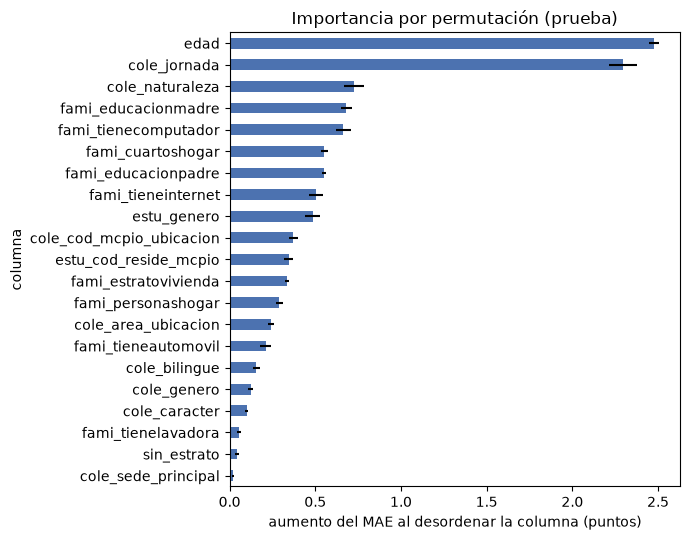

,aumento_mae,desviacion
columna,,
edad,2.476,0.027
cole_jornada,2.296,0.084
cole_naturaleza,0.725,0.059
fami_educacionmadre,0.682,0.030
fami_tienecomputador,0.663,0.043
fami_cuartoshogar,0.551,0.020
fami_educacionpadre,0.550,0.012
fami_tieneinternet,0.503,0.041
estu_genero,0.484,0.045


In [11]:
importance = results["importance"]
fig, ax = plt.subplots(figsize=(7, 5.5))
importance["aumento_mae"][::-1].plot.barh(ax=ax, xerr=importance["desviacion"][::-1], color="#4c72b0")
ax.set_xlabel("aumento del MAE al desordenar la columna (puntos)")
ax.set_title("Importancia por permutación (prueba)")
plt.tight_layout(); plt.show()
importance.round(3)

In [12]:
SENSITIVE = {"estu_genero": "género", "fami_estratovivienda": "estrato", "sin_estrato": "marca «Sin Estrato»",
             "cole_area_ubicacion": "zona", "cole_cod_mcpio_ubicacion": "municipio del colegio",
             "estu_cod_reside_mcpio": "municipio de residencia", "edad": "edad"}
ranking = {col: i + 1 for i, col in enumerate(importance.index)}
print("Atributos sensibles o de uso cuidadoso entre las variables del modelo:")
for col, label in SENSITIVE.items():
    r = importance.loc[col]
    print(f"  {label:26s} ({col}): puesto {ranking[col]:2d} de {len(importance)} · aumento del MAE {r.aumento_mae:.3f} (± {r.desviacion:.3f})")

Atributos sensibles o de uso cuidadoso entre las variables del modelo:
  género                     (estu_genero): puesto  9 de 21 · aumento del MAE 0.484 (± 0.045)
  estrato                    (fami_estratovivienda): puesto 12 de 21 · aumento del MAE 0.334 (± 0.011)
  marca «Sin Estrato»        (sin_estrato): puesto 20 de 21 · aumento del MAE 0.043 (± 0.014)
  zona                       (cole_area_ubicacion): puesto 14 de 21 · aumento del MAE 0.240 (± 0.018)
  municipio del colegio      (cole_cod_mcpio_ubicacion): puesto 10 de 21 · aumento del MAE 0.372 (± 0.027)
  municipio de residencia    (estu_cod_reside_mcpio): puesto 11 de 21 · aumento del MAE 0.345 (± 0.027)
  edad                       (edad): puesto  1 de 21 · aumento del MAE 2.476 (± 0.027)


## 8. Guardar los resultados de la etapa

`reports/07_metricas_test.json` (métricas, intervalos, metas; el notebook 08 las registra con el modelo),
`reports/07_equidad.csv` y `reports/07_importancia.csv`. El informe `reports/07_validacion.md` se escribe **con estas cifras**.

In [13]:
output = {
    "decisiones_congeladas": decisions["fecha_y_hora"],
    "prueba_abierta": MARKER.read_text(encoding="utf-8").strip(),
    "prueba": {"estudiantes": int(len(y_test)), "sedes": int(pd.unique(test_groups).size)},
    "modelo_final": decisions["modelo_final"],
    "metricas_modelo": m_model, "metricas_linea_base": m_base,
    "linea_base_constante": float(baseline.constant_.ravel()[0]),
    "intervalos_95_sedes": {
        idx: {"modelo": [r["_lo_m"], r["_hi_m"]], "linea_base": [r["_lo_b"], r["_hi_b"]],
              "diferencia": r["diferencia"], "diferencia_ic": [r["IC dif. inf."], r["IC dif. sup."]]}
        for idx, r in metrics.iterrows()},
    "mejora_a_linea_base_con_confianza": bool(beats_baseline),
    "metas": {"minima_38_puntual": bool(mae <= 38), "minima_38_ic_superior": bool(mae_hi <= 38),
              "deseable_35_puntual": bool(mae <= 35), "deseable_35_ic_superior": bool(mae_hi <= 35)},
    "equidad_resumen": {k: int(v) for k, v in summary.items()},
}
(REPORTS_DIR / "07_metricas_test.json").write_text(json.dumps(output, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
equity.round(4).to_csv(REPORTS_DIR / "07_equidad.csv", encoding="utf-8")
importance.round(4).to_csv(REPORTS_DIR / "07_importancia.csv", encoding="utf-8")
print("guardado: 07_metricas_test.json, 07_equidad.csv, 07_importancia.csv")

guardado: 07_metricas_test.json, 07_equidad.csv, 07_importancia.csv


## Entregable de esta etapa

- [x] Decisiones congeladas con fecha y hora **antes** de abrir la prueba (`reports/07_decisiones_congeladas.json`).
- [x] La prueba se abrió **una sola vez** (`reports/prueba_abierta.txt`); re-ejecutar no la vuelve a evaluar.
- [x] Métricas con intervalo por sedes, comparación con la línea base y con las metas.
- [x] Equidad por segmento con su veredicto, estudiantes y sedes.
- [x] Interpretación con importancia por permutación y sus límites.
- [x] `reports/07_validacion.md` completado con estas cifras.